# LAB 10 — K-Means Clustering
## Finding Customer Segments, Choosing K and Avoiding the Traps on Real Data

## Student Information
- **Name:** Manahil Fatima
- **Student ID:** 023-24-0249
- **Section:** H
- **GitHub:** https://github.com/ManahilFatima16/ml-lab10-kmeans-clustering
- **Kaggle:** https://www.kaggle.com/manahilmemon12
- **Dataset:** Mall Customers (Kaggle) + Wine (UCI)
- **Dataset Source:** https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python and https://archive.ics.uci.edu/dataset/109/wine

### Before You Start
- You studied K-Means in the lecture. This notebook does not teach it again; it makes you use it, test it and question it.
- There is **no target column**: no train/test split and no accuracy. Judge results by distances, silhouette, plots and common sense.
- Use `SEED = 42`. Write an interpretation under every table and plot. Place `Mall_Customers.csv` in the same folder as this notebook.
- `from sklearn.datasets import load_wine` loads the Wine data (no download needed).


---

## Part 0 — Setup and First Look (10 minutes)

Today there is no target column. The Mall Customers data has no 'right answer' for each customer, so we do not split into train and test and we cannot use accuracy. You will find groups with K-Means (your lecture) and judge them by distance, silhouette and common sense.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Unsupervised learning | Learning from data that has no labels. The goal is to find structure (groups), not to predict a column. | `No y, no train_test_split.` |
| Cluster | A group of points that are close to each other and far from the other groups. | `model.labels_ gives the cluster number of every row.` |
| Feature | One column used to describe each row (here Age, Income, Spending). | `df[['Income','Spending']].values` |


**First cell:** import everything you need (NumPy, Pandas, Matplotlib, KMeans, StandardScaler, PCA, load_wine, silhouette_score, silhouette_samples, adjusted_rand_score) and set `SEED = 42`.

In [1]:
# YOUR CODE HERE
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.datasets import load_wine

SEED = 42
np.random.seed(SEED)

### Task 0.1 — Load and check the data

Load Mall_Customers.csv and understand it in one cell.

1. Load the CSV. Rename 'Annual Income (k$)' to Income and 'Spending Score (1-100)' to Spending (shorter names).
2. Print the shape, the number of missing values, the number of duplicate rows and the count of each Gender.
3. Show describe() for Age, Income and Spending.


In [3]:
# YOUR CODE HERE
df = pd.read_csv('Mall_Customers.csv')
df = df.rename(columns={'Annual Income (k$)': 'Income',
                        'Spending Score (1-100)': 'Spending'})

print("Shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print(df['Gender'].value_counts())
display(df[['Age', 'Income', 'Spending']].describe())

Shape: (200, 5)
Missing values: 0
Duplicate rows: 0
Gender
Female    112
Male       88
Name: count, dtype: int64


,Age,Income,Spending
count,200.000000,200.000000,200.000000
mean,38.850000,60.560000,50.200000
std,13.969007,26.264721,25.823522
min,18.000000,15.000000,1.000000
25%,28.750000,41.500000,34.750000
50%,36.000000,61.500000,50.000000
75%,49.000000,78.000000,73.000000
max,70.000000,137.000000,99.000000


### Task 0.2 — Look at the data before clustering

Use your eyes first: draw three scatter plots side by side.

1. Draw Spending vs Income, Spending vs Age and Income vs Age (one row of three plots, axis labels and titles).


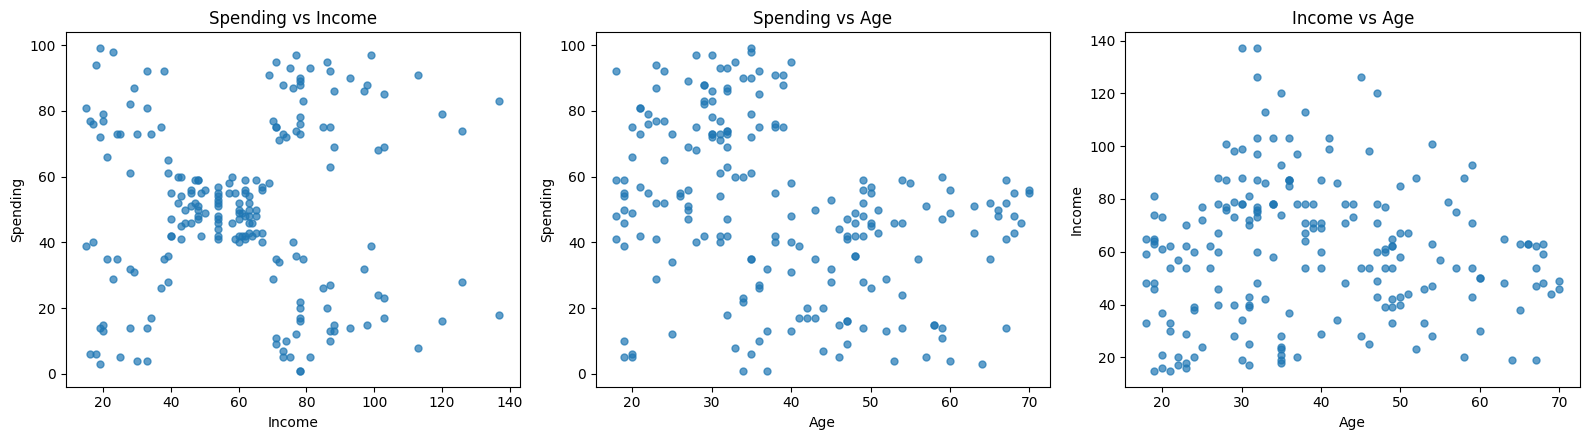

In [4]:
# YOUR CODE HERE
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
pairs = [('Income', 'Spending'), ('Age', 'Spending'), ('Age', 'Income')]
for a, (xc, yc) in zip(ax, pairs):
    a.scatter(df[xc], df[yc], s=25, alpha=0.7)
    a.set_xlabel(xc); a.set_ylabel(yc); a.set_title(f'{yc} vs {xc}')
plt.tight_layout(); plt.show()

**Questions** (answer with your own numbers)

(a) How many groups can you see by eye in each of the three plots? Which plot shows the groups most clearly?

(b) Why can we not use accuracy or a train/test split to judge a clustering result?



**Your answers:**

(a) Spending vs Income shows five clear groups of people based on their income and spending. Spending vs Age shows two loose groups: younger people spend more, while older people spend less. Income vs Age does not show any clear groups. Overall, Spending vs Income shows the best grouping.

(b) There is no target column, so we don't have correct labels to check. Accuracy and train/test split are used for labelled data. In clustering, we use all the data and check the groups using distances, silhouette score, graphs, and how well the groups make sense.


---

## Part 1 — K-Means From Scratch (35 minutes)

In the lecture you did K-Means by hand. Here you turn your pen-and-paper steps into code, check your answers against the lecture slides, and then build your own K-Means function and compare it with scikit-learn. Using KMeans() inside your own function is not allowed.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| K | The number of clusters. You choose it before running. | `KMeans(n_clusters=5)` |
| Centroid | The centre (mean) of a cluster. It is a point, not always a real row. | `model.cluster_centers_` |
| Distance | 1 feature: |x - m|. 2 or more features: Euclidean, sqrt of the sum of squared differences. | `np.abs(a-b)  or  np.sqrt(((a-b)**2).sum(axis=1))` |
| Assign step | Give each point to its nearest centroid. | `d.argmin(axis=1)` |
| Update step | Move each centroid to the mean of the points assigned to it. | `X[labels==k].mean(axis=0)` |
| Convergence | Stop when no point changes cluster (centroids stop moving). | `np.allclose(new_c, c)` |
| Inertia | Sum of squared distances from every point to its own centroid. Smaller = tighter clusters. | `model.inertia_` |
| Broadcasting | NumPy trick: x[:, None] - m[None, :] gives every point-to-centroid difference in one line. | `x[:, None, :] - C[None, :, :]` |


### Task 1.1 — Lecture Example 1 in code (one feature)

Reproduce the 9-number example from the lecture (2, 4, 10, 12, 3, 20, 30, 11, 25) with K = 2 and starting centroids 4 and 11.

1. Write a loop that, in every iteration, computes the distances, assigns the clusters, updates the centroids and prints both clusters and the new centroids.
2. Stop when no centroid changes. Print the final centroids and the inertia.
3. Compare with the lecture slides (final centroids 7 and 25, inertia 150).

**Hints:**
- Distance matrix: np.abs(x[:, None] - m[None, :]) has shape (9, 2).
- Cluster of each point: dist.argmin(axis=1).


In [5]:
# YOUR CODE HERE
x = np.array([2, 4, 10, 12, 3, 20, 30, 11, 25], dtype=float)
m = np.array([4.0, 11.0])
print("Start centroids:", m)
it = 0
while True:
    it += 1
    dist = np.abs(x[:, None] - m[None, :])
    lab = dist.argmin(axis=1)
    new_m = np.array([x[lab == k].mean() for k in range(2)])
    print(f"Iteration {it}: C1 = {x[lab==0].tolist()}  C2 = {x[lab==1].tolist()}  new centroids = {new_m.tolist()}")
    if np.allclose(new_m, m):
        print("No centroid changed, stop.")
        break
    m = new_m
inertia = sum(((x[lab == k] - m[k]) ** 2).sum() for k in range(2))
print("\nFinal centroids:", m, " Inertia:", inertia)
print("Lecture says centroids 7 and 25, inertia 150")

Start centroids: [ 4. 11.]
Iteration 1: C1 = [2.0, 4.0, 3.0]  C2 = [10.0, 12.0, 20.0, 30.0, 11.0, 25.0]  new centroids = [3.0, 18.0]
Iteration 2: C1 = [2.0, 4.0, 10.0, 3.0]  C2 = [12.0, 20.0, 30.0, 11.0, 25.0]  new centroids = [4.75, 19.6]
Iteration 3: C1 = [2.0, 4.0, 10.0, 12.0, 3.0, 11.0]  C2 = [20.0, 30.0, 25.0]  new centroids = [7.0, 25.0]
Iteration 4: C1 = [2.0, 4.0, 10.0, 12.0, 3.0, 11.0]  C2 = [20.0, 30.0, 25.0]  new centroids = [7.0, 25.0]
No centroid changed, stop.

Final centroids: [ 7. 25.]  Inertia: 150.0
Lecture says centroids 7 and 25, inertia 150


### Task 1.2 — Lecture Example 2 in code (two features)

Do the height/weight example: P1 (185, 72), P2 (170, 56), P3 (168, 60), P4 (179, 68), P5 (182, 72), P6 (188, 77). K = 2, start with P1 and P2.

1. Use Euclidean distance and the same loop idea. Print the cluster of every point and the centroids per iteration.
2. Print the final distance table and check one value by hand (the lecture shows d(P3, M2) = 4.47 in the first iteration).


In [7]:
P = np.array([[185, 72], [170, 56], [168, 60], [179, 68], [182, 72], [188, 77]], dtype=float)
M = P[[0, 1]].copy()
names = ["P1", "P2", "P3", "P4", "P5", "P6"]
it = 0
while True:
    it += 1
    D = np.sqrt(((P[:, None, :] - M[None, :, :]) ** 2).sum(axis=2))
    lab = D.argmin(axis=1)
    new_M = np.array([P[lab == k].mean(axis=0) for k in range(2)])
    print(f"Iteration {it}")
    print(pd.DataFrame(D.round(2), index=names, columns=["d to M1", "d to M2"]).assign(Cluster=["C" + str(l + 1) for l in lab]))
    print("New centroids:", new_M.round(2).tolist(), "\n")
    if np.allclose(new_M, M):
        break
    M = new_M
print("Check by hand: d(P3, M2) in iteration 1 = sqrt((168-170)^2 + (60-56)^2) =", round(np.sqrt(4 + 16), 2))

Iteration 1
    d to M1  d to M2 Cluster
P1     0.00    21.93      C1
P2    21.93     0.00      C2
P3    20.81     4.47      C2
P4     7.21    15.00      C1
P5     3.00    20.00      C1
P6     5.83    27.66      C1
New centroids: [[183.5, 72.25], [169.0, 58.0]] 

Iteration 2
    d to M1  d to M2 Cluster
P1     1.52    21.26      C1
P2    21.13     2.24      C2
P3    19.76     2.24      C2
P4     6.19    14.14      C1
P5     1.52    19.10      C1
P6     6.54    26.87      C1
New centroids: [[183.5, 72.25], [169.0, 58.0]] 

Check by hand: d(P3, M2) in iteration 1 = sqrt((168-170)^2 + (60-56)^2) = 4.47


### Task 1.3 — Write your own K-Means function

Write my_kmeans(X, init_centroids, max_iter=100) for any number of features.

1. Return four things: labels, final centroids, inertia and the number of iterations.
2. Test it on Example 1: it must give centroids 7 and 25 and inertia 150.
3. Think about what to do if a cluster ends up empty (keep its old centroid).


In [8]:
# YOUR CODE HERE
def my_kmeans(X, init_centroids, max_iter=100):
    X = np.asarray(X, dtype=float)
    if X.ndim == 1:
        X = X[:, None]
    C = np.asarray(init_centroids, dtype=float).copy()
    if C.ndim == 1:
        C = C[:, None]
    K = C.shape[0]
    labels = None
    n_iter = 0
    for n_iter in range(1, max_iter + 1):
        d = np.sqrt(((X[:, None, :] - C[None, :, :]) ** 2).sum(axis=2))
        new_labels = d.argmin(axis=1)
        if labels is not None and np.array_equal(new_labels, labels):
            break
        labels = new_labels
        for k in range(K):
            if (labels == k).any():          # empty cluster keeps its old centroid
                C[k] = X[labels == k].mean(axis=0)
    inertia = ((X - C[labels]) ** 2).sum()
    return labels, C, inertia, n_iter

In [9]:
# YOUR CODE HERE
lab, cen, inert, n = my_kmeans(x, [4, 11])
print("Labels:", lab)
print("Centroids:", cen.ravel(), " Inertia:", inert, " Iterations:", n)

Labels: [0 0 0 0 0 1 1 0 1]
Centroids: [ 7. 25.]  Inertia: 150.0  Iterations: 4


### Task 1.4 — Check your function against scikit-learn

Run your function and KMeans on the same data with the same starting centroids and compare.

1. Use X2 = Income and Spending (200 x 2). Take the first 5 rows as the starting centroids.
2. Run my_kmeans. Run KMeans(n_clusters=5, init=<your 5 rows>, n_init=1, tol=0, algorithm='lloyd').
3. Compare iterations, inertia, labels and centroids.


In [10]:
# YOUR CODE HERE
X2 = df[["Income", "Spending"]].values.astype(float)
init5 = X2[:5].copy()
lab_m, cen_m, inert_m, n_m = my_kmeans(X2, init5)
sk = KMeans(n_clusters=5, init=init5, n_init=1, tol=0, algorithm="lloyd").fit(X2)
print("my_kmeans : iterations", n_m, " inertia", round(inert_m, 4))
print("sklearn   : iterations", sk.n_iter_, " inertia", round(sk.inertia_, 4))
print("Labels identical   :", np.array_equal(lab_m, sk.labels_))
print("Centroids identical:", np.allclose(cen_m, sk.cluster_centers_))
print("Max centroid difference:", np.abs(cen_m - sk.cluster_centers_).max())

my_kmeans : iterations 4  inertia 44448.4554
sklearn   : iterations 4  inertia 44448.4554
Labels identical   : True
Centroids identical: True
Max centroid difference: 2.842170943040401e-14


**Questions** (answer with your own numbers)

(a) Example 1: the point 10 started in cluster C2 but moved to C1 in iteration 2. Explain why, using the centroid values.

(b) What makes the loop stop? Why is the stopping guaranteed even though the final answer is not always the best one?

(c) Did your function match scikit-learn exactly (labels, centroids, inertia)? If anything differed, explain why.

(d) What does a centroid mean for a group of customers? Why must the features be numeric for K-Means?



**Your answers:**

(a) In iteration 1 the centroids were 4 and 11. The point 10 is |10 - 4| = 6 from C1 but only |10 - 11| = 1 from C2, so it went to C2. After iteration 1 the centroids moved to 3 and 18. Now |10 - 3| = 7 and |10 - 18| = 8, so 10 is closer to C1 and it moved there in iteration 2.

(b) The loop stops when no point changes its cluster, so the centroids stop moving (in my run this happened at iteration 4). Stopping is guaranteed because both the assign step and the update step can only keep the inertia the same or lower it, and the number of ways to split the points is finite, so it cannot go on forever or go in circles. But it only reaches the nearest local minimum from its starting centroids, so it is not always the best answer.

(c) Yes, it matched exactly. Both took 4 iterations, both gave inertia 44448.4554, the labels are identical and the centroids are identical. The largest centroid difference was 2.8e-14, which is just floating point rounding. This is because I used the same starting centroids and the same assign and update steps.

(d) A centroid is the average customer of a group, for example the average Age, Income and Spending of that cluster. It is a typical profile and not always a real customer. Features must be numeric because K-Means needs to subtract values to get distances and take means. You cannot subtract or average text such as Male and Female without turning it into numbers first.

---

## Part 2 — Choosing K: Elbow and Silhouette (30 minutes)

The algorithm needs K before it starts, but nobody tells us K. The lecture gave two tools: the elbow (inertia) and the silhouette score. Here you use both, then calculate a silhouette by hand to prove you understand it.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Elbow method | Plot inertia for K = 2, 3, 4 ... Inertia always falls as K grows, so look for the K where the fall suddenly becomes small (the bend). | `model.inertia_ in a loop over K` |
| a | Average distance from a point to the other points in its own cluster (smaller = better). | `d[same_cluster].mean()` |
| b | Average distance from the point to the points of the nearest other cluster (larger = better). | `min over other clusters` |
| Silhouette s | s = (b - a) / max(a, b). Close to +1: well placed. Near 0: on the border. Negative: probably in the wrong cluster. | `silhouette_samples(X, labels)` |
| Average silhouette | The mean of s over all points. The K with the highest value is a good candidate. | `silhouette_score(X, labels)` |


### Task 2.1 — Elbow and silhouette for K = 2 to 10

Decide how many customer groups exist using Income and Spending (X2).

1. For K = 2 to 10 fit KMeans(n_clusters=K, n_init=10, random_state=SEED) and record the inertia and the average silhouette.
2. Show a table (K, Inertia, Silhouette) and two plots: elbow curve and silhouette bars.
3. Print the K with the highest silhouette.


 K    Inertia  Silhouette  Drop from previous K
 2 181363.596       0.297                   NaN
 3 106348.373       0.468             75015.223
 4  73679.789       0.493             32668.584
 5  44448.455       0.554             29231.334
 6  37233.815       0.540              7214.641
 7  30241.344       0.529              6992.471
 8  25036.418       0.455              5204.926
 9  21916.795       0.456              3119.623
10  20072.071       0.441              1844.724

K with the highest silhouette: 5


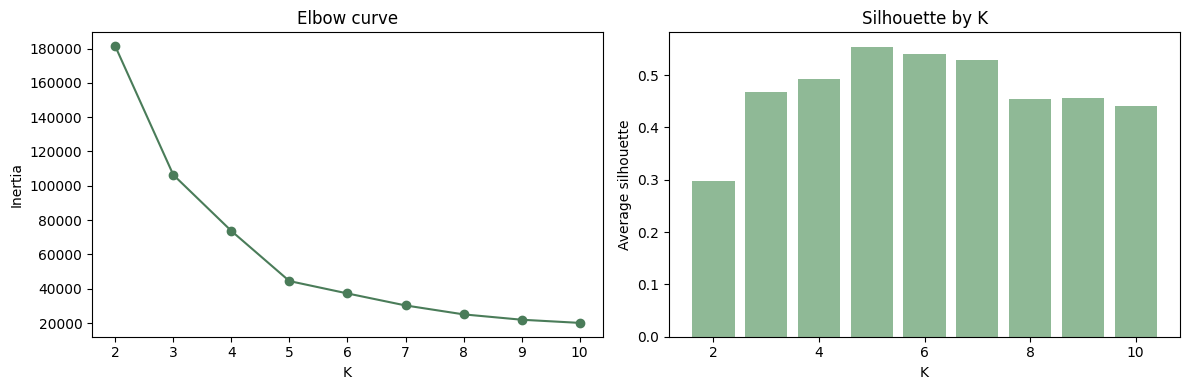

In [11]:
# YOUR CODE HERE
rows = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X2)
    rows.append((k, km.inertia_, silhouette_score(X2, km.labels_)))
res = pd.DataFrame(rows, columns=["K", "Inertia", "Silhouette"])
res["Drop from previous K"] = res["Inertia"].shift(1) - res["Inertia"]
print(res.round(3).to_string(index=False))
best_k = int(res.loc[res["Silhouette"].idxmax(), "K"])
print("\nK with the highest silhouette:", best_k)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(res["K"], res["Inertia"], marker="o", color="#4a7c59"); ax[0].set_xlabel("K"); ax[0].set_ylabel("Inertia"); ax[0].set_title("Elbow curve")
ax[1].bar(res["K"], res["Silhouette"], color="#8fb996"); ax[1].set_xlabel("K"); ax[1].set_ylabel("Average silhouette"); ax[1].set_title("Silhouette by K")
plt.tight_layout(); plt.show()

### Task 2.2 — Silhouette by hand

Prove that you understand the formula by calculating it yourself.

1. Fit K = 5. Write a function that returns a, b and s for one point (use only NumPy distances). Apply it to customer 1 (row 0) and compare with silhouette_samples.
2. Show the count, mean and minimum silhouette of every cluster, and the number of customers with a negative silhouette.
3. Draw a silhouette plot of all customers sorted inside each cluster.


In [12]:
# YOUR CODE HERE
def sil_point(X, labels, i):
    d = np.sqrt(((X - X[i]) ** 2).sum(axis=1))
    own = labels == labels[i]
    own[i] = False
    a = d[own].mean()
    b = min(d[labels == c].mean() for c in np.unique(labels) if c != labels[i])
    return a, b, (b - a) / max(a, b)

km5 = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(X2)
lab5 = km5.labels_
s5 = silhouette_samples(X2, lab5)
a, b, s = sil_point(X2, lab5, 0)
print(f"Customer 1 by hand: a = {a:.4f}, b = {b:.4f}, s = {s:.4f}")
print(f"silhouette_samples : s = {s5[0]:.4f}")

Customer 1 by hand: a = 24.6404, b = 42.2653, s = 0.4170
silhouette_samples : s = 0.4170


         Count   Mean    Min
Cluster                     
0           81  0.597  0.115
1           39  0.509  0.225
2           22  0.599  0.051
3           35  0.504 -0.023
4           23  0.512 -0.009

Customers with negative silhouette: 2
Overall average silhouette: 0.5539


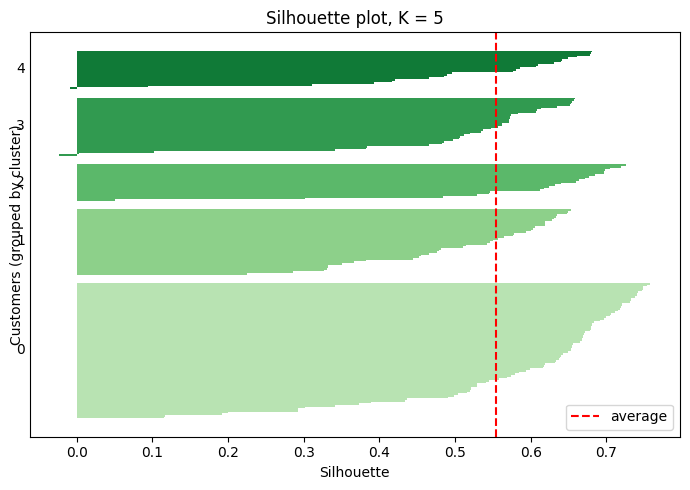

In [13]:
# YOUR CODE HERE
prof = pd.DataFrame({"Cluster": lab5, "s": s5}).groupby("Cluster")["s"].agg(Count="count", Mean="mean", Min="min").round(3)
print(prof)
print("\nCustomers with negative silhouette:", int((s5 < 0).sum()))
print("Overall average silhouette:", round(s5.mean(), 4))

fig, ax = plt.subplots(figsize=(7, 5))
y0 = 0
for c in range(5):
    v = np.sort(s5[lab5 == c])
    ax.barh(np.arange(y0, y0 + len(v)), v, height=1.0, color=plt.cm.Greens(0.3 + 0.13 * c))
    ax.text(-0.08, y0 + len(v) / 2, str(c), va="center")
    y0 += len(v) + 5
ax.axvline(s5.mean(), color="red", linestyle="--", label="average")
ax.set_xlabel("Silhouette"); ax.set_ylabel("Customers (grouped by cluster)"); ax.set_title("Silhouette plot, K = 5"); ax.set_yticks([]); ax.legend()
plt.tight_layout(); plt.show()

### Task 2.3 — The lecture practice problem

Points 1, 3, 5, 7, 11, 13, 15 with K = 2 and starting centroids 1 and 11 (the 'Practice' slide).

1. Run your my_kmeans on these points and print the final clusters, centroids and iterations.
2. Calculate a, b and s for the points 1, 7 and 11 with your function and compare with silhouette_samples.
3. Also write the iterations on paper (clusters and centroids after each iteration) and keep the photo or notes for your own revision.


In [14]:
# YOUR CODE HERE
pts = np.array([1, 3, 5, 7, 11, 13, 15], dtype=float)
lab, cen, inert, n = my_kmeans(pts, [1, 11])
print("Final C1:", pts[lab == 0].tolist(), " C2:", pts[lab == 1].tolist())
print("Centroids:", cen.ravel(), " Iterations (including the check pass):", n, " Inertia:", inert)
Xp = pts[:, None]
sp = silhouette_samples(Xp, lab)
for p in [1, 7, 11]:
    i = int(np.where(pts == p)[0][0])
    a, b, s = sil_point(Xp, lab, i)
    print(f"Point {p:>2}: a = {a:.2f}, b = {b:.2f}, s = {s:.3f}   silhouette_samples = {sp[i]:.3f}")

Final C1: [1.0, 3.0, 5.0, 7.0]  C2: [11.0, 13.0, 15.0]
Centroids: [ 4. 13.]  Iterations (including the check pass): 3  Inertia: 28.0
Point  1: a = 4.00, b = 12.00, s = 0.667   silhouette_samples = 0.667
Point  7: a = 4.00, b = 6.00, s = 0.333   silhouette_samples = 0.333
Point 11: a = 3.00, b = 7.00, s = 0.571   silhouette_samples = 0.571


**Questions** (answer with your own numbers)

(a) Which K does the elbow suggest and which K does the silhouette suggest? Do they agree? Quote the numbers (for example how much the inertia drops from K=4 to 5 and from 5 to 6).

(b) What is the silhouette of customer 1 and what does it tell you? Which cluster has the weakest average silhouette and how many customers have a negative value?

(c) In the practice problem, is point 1 or point 7 less well placed? Explain using a and b.

(d) Why should we never choose K only by the lowest inertia?



**Your answers:**

(a) The elbow method suggests K = 5 because the inertia drops a lot from K=4 to K=5, but after K=5 the drop becomes smaller. The silhouette score is also highest at K=5 (0.554). So, both methods suggest 5 clusters.

(b) Customer 1 has a silhouette score of 0.417, which means it belongs to its cluster but is near the edge. Cluster 3 has the lowest average score (0.504). Only 2 customers have negative scores, meaning they are close to the wrong cluster.

(c) Point 7 is less clearly placed than point 1. Both have a = 4, but point 7 is closer to the other cluster (b = 6). That is why point 7 changed its cluster in iteration 2.

(d) Inertia always decreases when we increase K. If every customer gets its own cluster, inertia becomes 0, but the clusters are not useful. So, we use the elbow method and silhouette score to choose the best K.

---

## Part 3 — Starting Points and Stability (20 minutes)

The lecture said 'starting points matter - run several starts and keep the best'. You will now measure how much, using the same data and the same K.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Local minimum | A solution that cannot be improved by the assign/update loop but is not the best possible one. | `A higher final inertia than the best run.` |
| init='random' | Pick K random rows as the starting centroids. | `KMeans(init='random')` |
| init='k-means++' | Pick starting centroids that are far from each other. This is the default and is usually better. | `KMeans(init='k-means++')` |
| n_init | How many different starts to try. scikit-learn keeps the run with the lowest inertia. | `KMeans(n_init=10)` |
| Adjusted Rand Index (ARI) | Agreement between two groupings. 1 = same groups, about 0 = no better than random. It ignores the cluster numbers (cluster 2 in one run can be cluster 4 in another). | `adjusted_rand_score(a, b)` |


### Task 3.1 — 30 different seeds

Measure how often K-Means finds the best answer.

1. With K = 5 on X2, run KMeans 30 times (random_state = 0 to 29) in three settings: init='random' with n_init=1, k-means++ with n_init=1, k-means++ with n_init=10.
2. Build a table: setting, number of distinct final inertia values (round to 1 decimal), lowest, highest, and the percentage of runs that reached the best inertia.
3. Draw one histogram of the final inertia values for the three settings.


             Setting  Distinct inertia values  Lowest  Highest  % runs at best
    random, n_init=1                       14 44448.5  91762.0            33.3
 k-means++, n_init=1                        6 44448.5  66733.4            60.0
k-means++, n_init=10                        1 44448.5  44448.5           100.0

Best inertia found anywhere: 44448.5


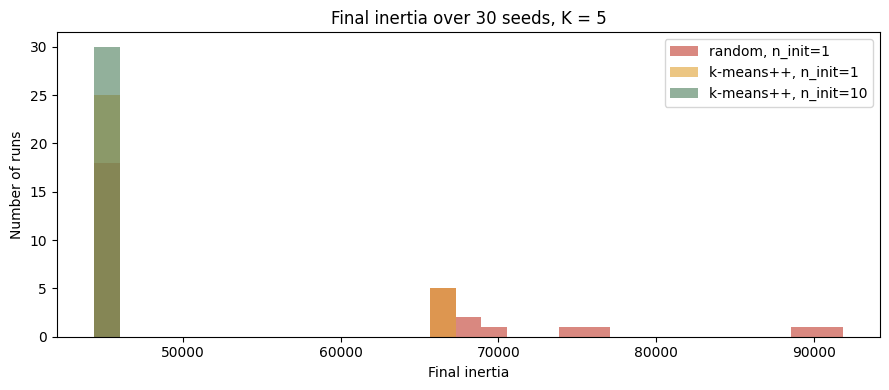

In [15]:
# YOUR CODE HERE
settings = [("random, n_init=1", dict(init="random", n_init=1)),
            ("k-means++, n_init=1", dict(init="k-means++", n_init=1)),
            ("k-means++, n_init=10", dict(init="k-means++", n_init=10))]
runs = {}
for name, kw in settings:
    runs[name] = [KMeans(n_clusters=5, random_state=s, **kw).fit(X2) for s in range(30)]
rows = []
for name, _ in settings:
    inn = np.array([r.inertia_ for r in runs[name]])
    best = inn.min()
    rows.append((name, len(set(inn.round(1))), round(inn.min(), 1), round(inn.max(), 1), round(100 * np.mean(np.isclose(inn, best, atol=0.05)), 1)))
stab = pd.DataFrame(rows, columns=["Setting", "Distinct inertia values", "Lowest", "Highest", "% runs at best"])
print(stab.to_string(index=False))
overall_best = min(r.inertia_ for v in runs.values() for r in v)
print("\nBest inertia found anywhere:", round(overall_best, 1))
plt.figure(figsize=(9, 4))
allv = np.concatenate([[r.inertia_ for r in runs[n]] for n, _ in settings])
bins = np.linspace(allv.min() - 50, allv.max() + 50, 30)
for (name, _), col in zip(settings, ["#c0392b", "#e0a030", "#4a7c59"]):
    plt.hist([r.inertia_ for r in runs[name]], bins=bins, alpha=0.6, label=name, color=col)
plt.xlabel("Final inertia"); plt.ylabel("Number of runs"); plt.title("Final inertia over 30 seeds, K = 5"); plt.legend()
plt.tight_layout(); plt.show()

### Task 3.2 — Best run vs worst run

See what a bad local minimum looks like.

1. From the random-init runs take the best and the worst. Draw both clusterings with their centroids side by side.
2. Print their inertia and their ARI.


Best random run : seed 0  inertia 44448.5
Worst random run: seed 13  inertia 91762.0
ARI between best and worst: 0.4553


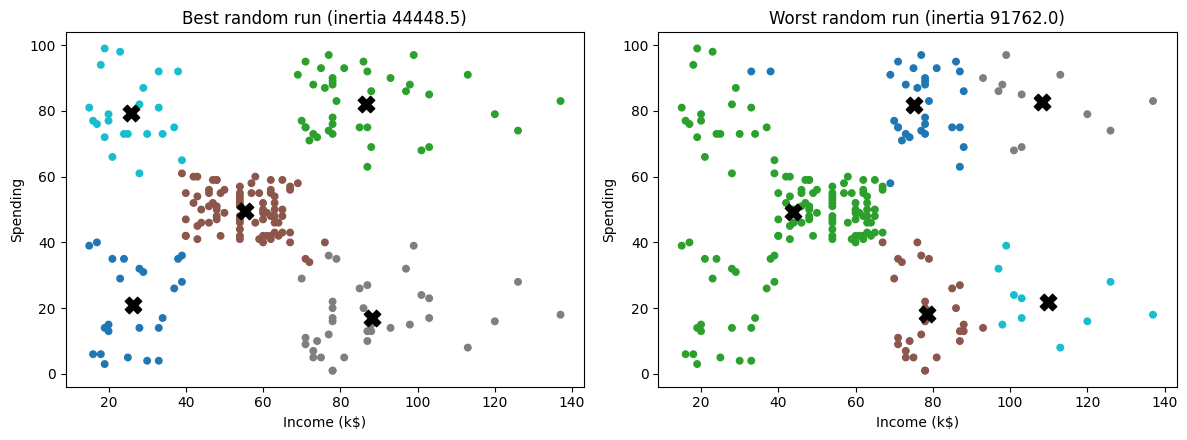

In [16]:
# YOUR CODE HERE
rr = runs["random, n_init=1"]
inn = np.array([r.inertia_ for r in rr])
rb, rw = rr[int(inn.argmin())], rr[int(inn.argmax())]
print("Best random run : seed", int(inn.argmin()), " inertia", round(rb.inertia_, 1))
print("Worst random run: seed", int(inn.argmax()), " inertia", round(rw.inertia_, 1))
print("ARI between best and worst:", round(adjusted_rand_score(rb.labels_, rw.labels_), 4))
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for a, r, t in zip(ax, [rb, rw], ["Best random run", "Worst random run"]):
    a.scatter(X2[:, 0], X2[:, 1], c=r.labels_, cmap="tab10", s=22)
    a.scatter(r.cluster_centers_[:, 0], r.cluster_centers_[:, 1], c="black", marker="X", s=140)
    a.set_xlabel("Income (k$)"); a.set_ylabel("Spending"); a.set_title(f"{t} (inertia {r.inertia_:.1f})")
plt.tight_layout(); plt.show()

**Questions** (answer with your own numbers)

(a) How many different final inertia values did the random-start setting produce, and what percentage of its runs reached the best one? Compare with the other two settings.

(b) Why can the same data and the same K give different answers?

(c) How do k-means++ and n_init help? What did n_init=10 give in your table?

(d) Why do we use ARI to compare two clusterings instead of comparing the label numbers directly?



**Your answers:**

(a) Random start produced 14 different inertia values, and only 33.3% of runs found the best result. K-means++ with n_init=1 performed better, while n_init=10 gave the best result in all runs (100%).

(b) K-means depends on its starting points. Different starting points can produce different results. The worst random run had almost double the inertia of the best run.

(c) K-means++ selects better starting points, so it gives better results. The n_init=10 setting runs the algorithm 10 times and keeps the best result.

(d) Cluster numbers are just labels. Two runs can have the same groups but different cluster numbers. ARI compares the actual groups, not their numbers. 1 means same groups, while 0 means random grouping. My best and worst runs have an ARI of 0.4553.


---

## Part 4 — Scaling: Units Decide the Clusters (25 minutes)

The lecture warned: 'Rs 5000 would swamp 3 visits'. You will prove it twice: once by only changing the unit of Income, and once on the Wine data where the features have very different sizes and the true groups are known.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Feature scaling | Putting all features on a similar scale so that no feature wins the distance only because its numbers are bigger. | `StandardScaler().fit_transform(X)` |
| StandardScaler | z = (x - mean) / std. Every column gets mean 0 and standard deviation 1. | `StandardScaler()` |
| External check | Comparing clusters with known true groups. Possible only for teaching data like Wine. Real clustering problems have no labels. | `adjusted_rand_score(y_true, labels)` |
| PCA (Lab 8) | Reduces many features to 2 so we can draw the data. Used here only for the plot. | `PCA(n_components=2)` |


### Task 4.1 — Change the unit, change the clusters

Use Age and Income with K = 4. Income is in thousands of dollars (15 to 137). Make a second copy where Income is in dollars (multiply by 1000).

1. Cluster four versions: raw k$, raw dollars, scaled k$, scaled dollars (StandardScaler, n_init=10, random_state=SEED).
2. Print ARI between: raw k$ vs raw dollars, scaled k$ vs scaled dollars, raw dollars vs scaled dollars.
3. Draw Age vs Income (in k$) coloured by the clusters of raw k$, raw dollars and scaled.


ARI raw k$ vs raw dollars      : 0.4897
ARI scaled k$ vs scaled dollars: 1.0
ARI raw dollars vs scaled dollars: 0.3605
ARI raw k$ vs scaled k$ (extra) : 0.7701


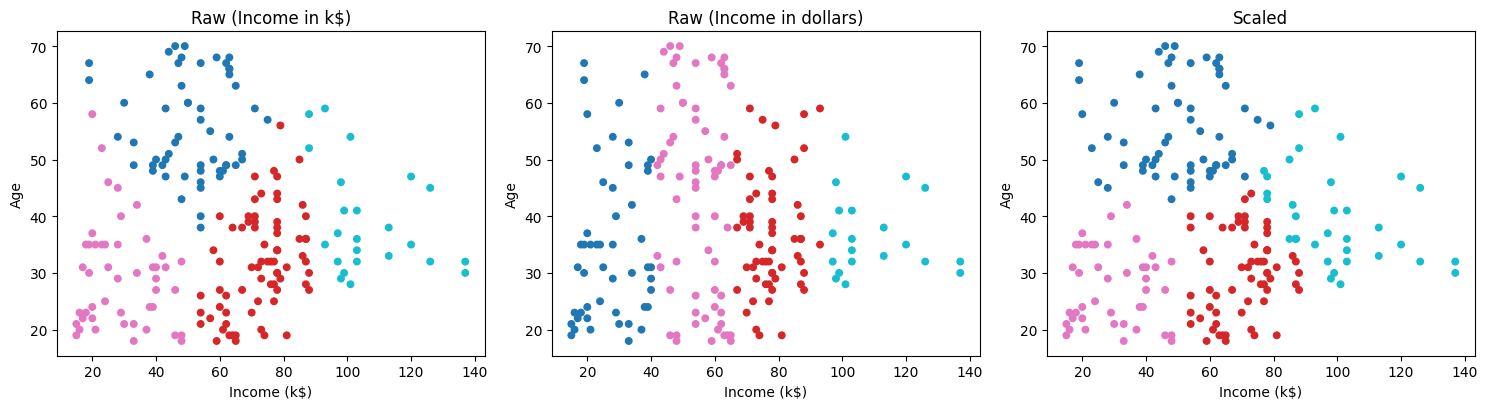

In [17]:
# YOUR CODE HERE
AI = df[["Age", "Income"]].values.astype(float)
AI_d = AI.copy(); AI_d[:, 1] = AI_d[:, 1] * 1000
def fit4(X):
    return KMeans(n_clusters=4, n_init=10, random_state=SEED).fit(X)
m_raw_k = fit4(AI)
m_raw_d = fit4(AI_d)
m_sc_k = fit4(StandardScaler().fit_transform(AI))
m_sc_d = fit4(StandardScaler().fit_transform(AI_d))
print("ARI raw k$ vs raw dollars      :", round(adjusted_rand_score(m_raw_k.labels_, m_raw_d.labels_), 4))
print("ARI scaled k$ vs scaled dollars:", round(adjusted_rand_score(m_sc_k.labels_, m_sc_d.labels_), 4))
print("ARI raw dollars vs scaled dollars:", round(adjusted_rand_score(m_raw_d.labels_, m_sc_d.labels_), 4))
print("ARI raw k$ vs scaled k$ (extra) :", round(adjusted_rand_score(m_raw_k.labels_, m_sc_k.labels_), 4))
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
for a, m_, t in zip(ax, [m_raw_k, m_raw_d, m_sc_k], ["Raw (Income in k$)", "Raw (Income in dollars)", "Scaled"]):
    a.scatter(AI[:, 1], AI[:, 0], c=m_.labels_, cmap="tab10", s=22)
    a.set_xlabel("Income (k$)"); a.set_ylabel("Age"); a.set_title(t)
plt.tight_layout(); plt.show()

### Task 4.2 — Wine data: raw vs scaled

Load the Wine data with load_wine(): 178 wines, 13 chemical measurements, 3 true grape cultivars. The true cultivar is used ONLY to check the result, never to fit K-Means.

1. Print the three largest and the smallest standard deviation of the features.
2. Run KMeans(K=3, n_init=10, random_state=SEED) on the raw data and on the scaled data. For each report ARI against the true cultivar, silhouette score and cluster sizes.


In [18]:
# YOUR CODE HERE
wine = load_wine()
XW = wine.data; yW = wine.target
sd = pd.Series(XW.std(axis=0), index=wine.feature_names).sort_values(ascending=False)
print("Three largest standard deviations:")
print(sd.head(3).round(3))
print("\nSmallest standard deviation:")
print(sd.tail(1).round(4))
print("\nRatio largest / smallest:", round(sd.iloc[0] / sd.iloc[-1], 1))

Three largest standard deviations:
proline              314.022
magnesium             14.242
alcalinity_of_ash      3.330
dtype: float64

Smallest standard deviation:
nonflavanoid_phenols    0.1241
dtype: float64

Ratio largest / smallest: 2530.3


In [19]:
# YOUR CODE HERE
XWs = StandardScaler().fit_transform(XW)
km_wr = KMeans(n_clusters=3, n_init=10, random_state=SEED).fit(XW)
km_ws = KMeans(n_clusters=3, n_init=10, random_state=SEED).fit(XWs)
wtab = pd.DataFrame({
    "Version": ["Raw", "Scaled"],
    "ARI vs true cultivar": [adjusted_rand_score(yW, km_wr.labels_), adjusted_rand_score(yW, km_ws.labels_)],
    "Silhouette": [silhouette_score(XW, km_wr.labels_), silhouette_score(XWs, km_ws.labels_)],
    "Cluster sizes": [np.bincount(km_wr.labels_).tolist(), np.bincount(km_ws.labels_).tolist()]})
print(wtab.round(4).to_string(index=False))
print("True cultivar sizes:", np.bincount(yW).tolist())

Version  ARI vs true cultivar  Silhouette Cluster sizes
    Raw                0.3711      0.5711  [62, 47, 69]
 Scaled                0.8975      0.2849  [65, 51, 62]
True cultivar sizes: [59, 71, 48]


### Task 4.3 — Draw it

Compare the three views in one picture.

1. Use one PCA of the scaled data and draw three plots with the same axes: true cultivars, raw clusters, scaled clusters.


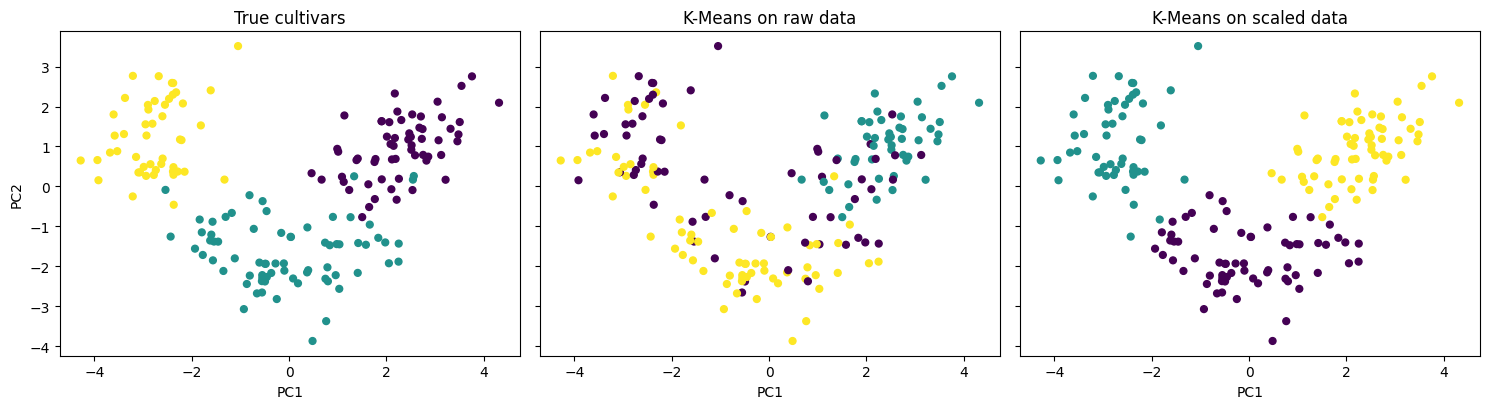

In [20]:
# YOUR CODE HERE
Z = PCA(n_components=2, random_state=SEED).fit_transform(XWs)
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2), sharex=True, sharey=True)
for a, lab_, t in zip(ax, [yW, km_wr.labels_, km_ws.labels_], ["True cultivars", "K-Means on raw data", "K-Means on scaled data"]):
    a.scatter(Z[:, 0], Z[:, 1], c=lab_, cmap="viridis", s=24)
    a.set_xlabel("PC1"); a.set_title(t)
ax[0].set_ylabel("PC2")
plt.tight_layout(); plt.show()

**Questions** (answer with your own numbers)

(a) What happened when only the unit of Income changed? Explain it with the distance formula (which feature controls the distance now?).

(b) On the Wine data which feature dominated the raw distance and how big is its standard deviation compared with the others? What were the ARI values raw vs scaled?

(c) The silhouette was higher on the raw Wine data although the clustering was worse. Explain why a silhouette can mislead here and why comparing it between raw and scaled data is not fair.

(d) In a real project with no labels, how will you decide whether to scale? Write your rule in one or two sentences.



**Your answers:**

(a) Income values are much larger than Age values, so Income dominates the distance and Age is almost ignored. Changing the income unit also changes the clusters (ARI = 0.4897). After scaling, both results become the same (ARI = 1.0).

(b) Proline has a much larger standard deviation (314.02) than the other features, so it dominates the distance. The ARI improves from 0.3711 on raw data to 0.8975 after scaling.

(c) Silhouette is higher on raw data (0.5711) because Proline dominates the distances. After scaling, all 13 features contribute, so the silhouette becomes lower (0.2849). However, the clustering matches the real groups better. A high silhouette does not always mean better clusters.

(d) I scale the data when features have different units or very different values. I check their ranges and standard deviations first. I avoid scaling when all features are already on a similar scale and their original values are important. In Mall data, Income and Spending have almost the same standard deviation, so scaling does not change the clusters (ARI = 1.0).


---

## Part 5 — Outliers and Anomalies (20 minutes)

The lecture said 'one extreme point drags a centroid'. You will add one extreme customer, see the damage, and then catch it with a distance rule (the anomaly detection idea from the lecture).

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Outlier | A point far away from all the others. K-Means uses means and squared distances, so one outlier has a big effect. | `A very large distance to the nearest centroid.` |
| Distance to own centroid | How far a point is from the centre of its cluster. Large = the point does not fit any group well. | `model.transform(X).min(axis=1)` |
| mean + 3 std rule | Flag a point if its distance is larger than the mean distance plus 3 standard deviations. | `d > d.mean() + 3*d.std()` |
| Anomaly detection | Using the clusters to find strange points (far from every centroid). | `Sort by the distance column.` |


### Task 5.1 — One extreme customer

Add one extra row to X2: Income = 400, Spending = 99. Use K = 5 on Income and Spending.

1. Fit KMeans (n_init=10, random_state=SEED) without and with the extra customer.
2. Print the cluster sizes, the centroids (sorted by income) and the ARI between the two results on the original 200 customers.
3. Draw the two clusterings side by side.


In [21]:
# YOUR CODE HERE
extra = np.array([[400.0, 99.0]])
Xo = np.vstack([X2, extra])
m_a = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(X2)
m_b = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(Xo)
def cen_table(m_):
    t = pd.DataFrame(m_.cluster_centers_.round(1), columns=["Income", "Spending"])
    t["Size"] = np.bincount(m_.labels_)
    return t.sort_values("Income").reset_index(drop=True)
print("Without the extra customer:"); print(cen_table(m_a))
print("\nWith the extra customer (Income 400, Spending 99):"); print(cen_table(m_b))
print("\nARI on the original 200 customers:", round(adjusted_rand_score(m_a.labels_, m_b.labels_[:200]), 4))

Without the extra customer:
   Income  Spending  Size
0    25.7      79.4    22
1    26.3      20.9    23
2    55.3      49.5    81
3    86.5      82.1    39
4    88.2      17.1    35

With the extra customer (Income 400, Spending 99):
   Income  Spending  Size
0    26.3      20.9    23
1    48.3      56.5   100
2    86.5      82.1    39
3    87.0      18.6    38
4   400.0      99.0     1

ARI on the original 200 customers: 0.7532


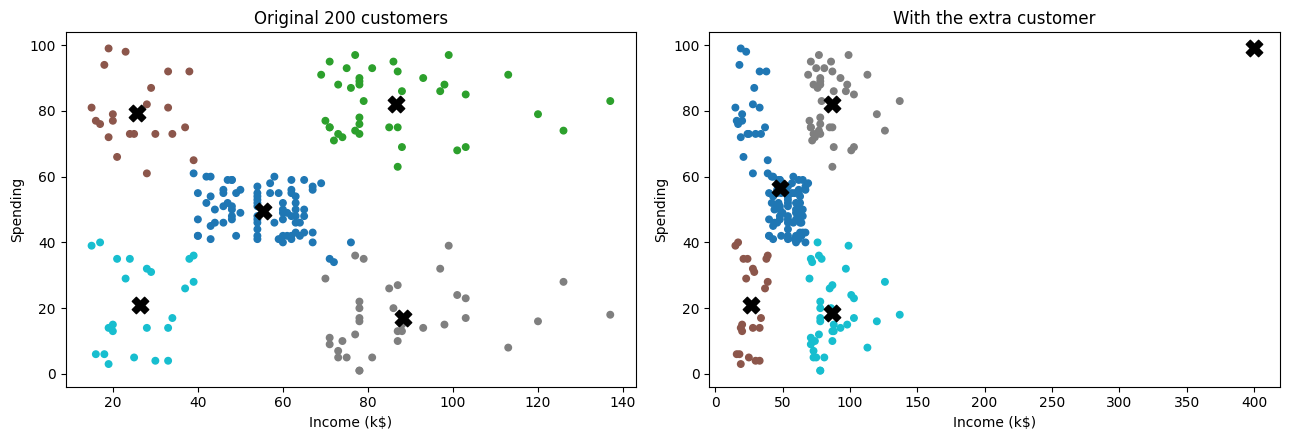

In [22]:
# YOUR CODE HERE
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].scatter(X2[:, 0], X2[:, 1], c=m_a.labels_, cmap="tab10", s=22)
ax[0].scatter(m_a.cluster_centers_[:, 0], m_a.cluster_centers_[:, 1], c="black", marker="X", s=140)
ax[0].set_title("Original 200 customers")
ax[1].scatter(Xo[:, 0], Xo[:, 1], c=m_b.labels_, cmap="tab10", s=22)
ax[1].scatter(m_b.cluster_centers_[:, 0], m_b.cluster_centers_[:, 1], c="black", marker="X", s=140)
ax[1].set_title("With the extra customer")
for a in ax:
    a.set_xlabel("Income (k$)"); a.set_ylabel("Spending")
plt.tight_layout(); plt.show()

### Task 5.2 — Catch it and repair

Use the model fitted on the original 200 customers.

1. Compute every customer's distance to its nearest centroid, and the distance of the extra customer to the nearest centroid of the same model.
2. Apply the rule mean + 3 std (mean and std from the 200 real customers). How many real customers are flagged? Is the extra customer flagged?
3. Show the 5 real customers that are farthest from their centroid (CustomerID, Age, Income, Spending, Cluster, Distance).
4. Remove all flagged points, refit K = 5 and report the cluster sizes and the ARI against the original model on the 200 customers (use predict).


In [23]:
# YOUR CODE HERE
dist = m_a.transform(X2).min(axis=1)
d_extra = m_a.transform(extra).min()
thr = dist.mean() + 3 * dist.std()
flag = dist > thr
print(f"mean = {dist.mean():.2f}, std = {dist.std():.2f}, threshold = {thr:.2f}")
print("Distance of the extra customer:", round(d_extra, 2), " flagged:", bool(d_extra > thr))
print("Real customers flagged:", int(flag.sum()))
out = df.assign(Cluster=m_a.labels_, Distance=dist.round(2))
print("\nFive real customers farthest from their centroid:")
print(out.sort_values("Distance", ascending=False).head(5)[["CustomerID", "Age", "Income", "Spending", "Cluster", "Distance"]].to_string(index=False))
m_fix = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(X2[~flag])
print("\nAfter removing flagged points: cluster sizes", np.bincount(m_fix.labels_).tolist(), " points kept:", int((~flag).sum()))
print("ARI vs original model on the 200 customers (predict):", round(adjusted_rand_score(m_a.labels_, m_fix.predict(X2)), 4))

mean = 13.02, std = 7.26, threshold = 34.80
Distance of the extra customer: 313.92  flagged: True
Real customers flagged: 4

Five real customers farthest from their centroid:
 CustomerID  Age  Income  Spending  Cluster  Distance
        200   30     137        83        1     50.47
        199   32     137        18        3     48.81
        198   32     126        74        1     40.29
        197   45     126        28        3     39.34
        196   35     120        79        1     33.61

After removing flagged points: cluster sizes [80, 34, 23, 37, 22]  points kept: 196
ARI vs original model on the 200 customers (predict): 0.9847


**Questions** (answer with your own numbers)

(a) What did the single extreme customer do to the clusters? Which real groups were affected? Use sizes and centroids.

(b) How well did the rule detect the extra customer? The rule also flagged some real customers: are they mistakes in the data or something worth looking at? Look at their Income and Spending.

(c) Name two ways to deal with outliers and one risk of simply deleting them.



**Your answers:**

(a) The extreme customer (400, 99) created a separate cluster of its own. Since K is still 5, the other 200 customers had to fit into 4 clusters. As a result, the low income/high spending group merged with the middle group. Other groups stayed almost the same. The ARI dropped to 0.7532, showing that the clusters changed.

(b) The method detected the extreme customer because its distance (313.92) was much higher than the threshold (34.80). It also detected 4 other rich customers. They are not mistakes; they simply have very high incomes.

(c) We can handle outliers in three ways:
1. Remove them if they are data errors.
2. Reduce their effect by capping values or using K-Medoids or DBSCAN.
3. Keep them as a separate group.
Removing outliers can be risky because some may be real and important customers. In my results, removing the 4 flagged customers gave an ARI of 0.9847, meaning the clusters stayed almost the same.

---

## Part 6 — From Clusters to Customer Segments (25 minutes)

Clusters are numbers (0, 1, 2 ...). The business needs names and actions. Cluster numbers are arbitrary labels: cluster 3 in one run has no meaning by itself. Use the original 200 customers and K = 5 on Income and Spending (random_state=SEED).

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Cluster profile | The average of every feature inside each cluster, plus the cluster size. This is how you read what a cluster means. | `df.groupby('Cluster').agg(...)` |
| Segment | A cluster with a name and an action, for example 'High income / Low spending'. | `df['Cluster'].map(names)` |
| Crosstab | Counts or percentages of one category inside another (Gender inside Segment). | `pd.crosstab(a, b, normalize='index')` |


### Task 6.1 — Profile and name the segments

Make the clustering readable for a manager.

1. Add the cluster number to the data. Build a profile table: number of customers, mean Age, mean Income, mean Spending and % female for each cluster, sorted by Income.
2. Create segment names with a small rule (Income below 40 = Low, 70 or more = High, otherwise Mid; Spending below 35 = Low, 65 or more = High, otherwise Mid). Print the size of each segment.


In [24]:
# YOUR CODE HERE
df["Cluster"] = km5.labels_
prof6 = df.groupby("Cluster").agg(Customers=("CustomerID", "count"), Age=("Age", "mean"), Income=("Income", "mean"),
                                  Spending=("Spending", "mean"), Pct_female=("Gender", lambda g: 100 * (g == "Female").mean())).round(1)
prof6 = prof6.sort_values("Income")
print(prof6)

         Customers   Age  Income  Spending  Pct_female
Cluster                                               
2               22  25.3    25.7      79.4        59.1
4               23  45.2    26.3      20.9        60.9
0               81  42.7    55.3      49.5        59.3
1               39  32.7    86.5      82.1        53.8
3               35  41.1    88.2      17.1        45.7


In [25]:
# YOUR CODE HERE
def seg_name(inc, spend):
    i = "Low" if inc < 40 else ("High" if inc >= 70 else "Mid")
    s = "Low" if spend < 35 else ("High" if spend >= 65 else "Mid")
    return f"{i} income / {s} spending"
cname = {c: seg_name(prof6.loc[c, "Income"], prof6.loc[c, "Spending"]) for c in prof6.index}
df["Segment"] = df["Cluster"].map(cname)
print(pd.DataFrame({"Cluster": list(cname.keys()), "Segment": list(cname.values())}).to_string(index=False))
print("\nSegment sizes:")
print(df["Segment"].value_counts())

 Cluster                     Segment
       2  Low income / High spending
       4   Low income / Low spending
       0   Mid income / Mid spending
       1 High income / High spending
       3  High income / Low spending

Segment sizes:
Segment
Mid income / Mid spending      81
High income / High spending    39
High income / Low spending     35
Low income / Low spending      23
Low income / High spending     22
Name: count, dtype: int64


### Task 6.2 — Does Gender matter? Does Age matter?

Gender and Age were not used in the clusters. Check whether they would add something.

1. Show the % of women in each segment and the overall %.
2. Scale Age, Income and Spending together and print the average silhouette for K = 2 to 8.


In [27]:
# YOUR CODE HERE
overall_f = 100 * (df["Gender"] == "Female").mean()
print("Overall % female:", round(overall_f, 1))
print("\n% of each gender inside each segment:")
print((pd.crosstab(df["Segment"], df["Gender"], normalize="index") * 100).round(1))
X3 = StandardScaler().fit_transform(df[["Age", "Income", "Spending"]])
rows = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X3)
    rows.append((k, silhouette_score(X3, km.labels_)))
sil3 = pd.DataFrame(rows, columns=["K", "Silhouette (Age, Income, Spending, scaled)"])
print("\n", sil3.round(4).to_string(index=False))
best3 = int(sil3.loc[sil3.iloc[:, 1].idxmax(), "K"])
print("Best K:", best3)

Overall % female: 56.0

% of each gender inside each segment:
Gender                       Female  Male
Segment                                  
High income / High spending    53.8  46.2
High income / Low spending     45.7  54.3
Low income / High spending     59.1  40.9
Low income / Low spending      60.9  39.1
Mid income / Mid spending      59.3  40.7

  K  Silhouette (Age, Income, Spending, scaled)
 2                                      0.3355
 3                                      0.3578
 4                                      0.4040
 5                                      0.4166
 6                                      0.4284
 7                                      0.4172
 8                                      0.4082
Best K: 6


### Task 6.3 — A three-feature alternative

Cluster the scaled Age, Income and Spending with the best K from the table above.

1. Fit it, build its profile table (size, Age, Income, Spending) sorted by Age.
2. Print the ARI between this segmentation and your 2-feature K = 5 segmentation.


In [28]:
km3 = KMeans(n_clusters=best3, n_init=10, random_state=SEED).fit(X3)
df["Cluster3"] = km3.labels_
prof3 = df.groupby("Cluster3").agg(Customers=("CustomerID", "count"), Age=("Age", "mean"), Income=("Income", "mean"),
                                   Spending=("Spending", "mean")).round(1).sort_values("Age")
print(prof3)
print("\nARI between 3-feature segmentation and 2-feature K=5:", round(adjusted_rand_score(df["Cluster"], df["Cluster3"]), 4))

          Customers   Age  Income  Spending
Cluster3                                   
4                23  25.0    25.3      77.6
1                39  26.8    57.1      48.1
3                39  32.7    86.5      82.1
2                33  41.9    88.9      17.0
5                21  45.5    26.3      19.4
0                45  56.3    54.3      49.1

ARI between 3-feature segmentation and 2-feature K=5: 0.7002


**Questions** (answer with your own numbers)

(a) Give each of the 5 segments a short business name and one concrete action (an offer or a message). Use the numbers from your profile table.

(b) Which segment is the most valuable now and which one is the biggest opportunity? Why?

(c) Does Gender help to separate the segments? Quote the percentages.

(d) Does adding Age change the story? Which segmentation would you present and why? (Careful: silhouette values from different feature sets are not directly comparable.)



**Your answers:**

(a) Customer Segments and Actions
- Young Enthusiasts: 22 customers with low income but high spending. Offer student discounts, loyalty rewards and instalment plans.
- Budget Savers: 23 customers with low income and low spending. Offer discount coupons and affordable packages.
- Everyday Shoppers: 81 customers with medium income and spending. Offer loyalty points and seasonal discounts.
- VIP Spenders: 39 customers with high income and high spending. Offer premium memberships, early access and personal services.
- Untapped Wealth: 35 customers with high income but low spending. Offer premium deals to encourage them to spend more.
(b) VIP Spenders are the most valuable because they have the highest spending. Untapped Wealth is the biggest opportunity because they have high income but spend very little. The Mid group is also important because it has the most customers (81).

(c) Gender does not make much difference because the percentage of women is almost similar across all clusters. So, Gender is not a useful feature for separating these customer groups.

(d) Adding Age changes the best K from 5 to 6. It divides the middle group into younger and older customers. However, most customers remain in similar groups (ARI = 0.7002). I would choose the 2-feature K=5 model because it is simpler and its groups are easier to understand. Age can be used as extra information for marketing.

---

## Part 7 — Final Output and Wrap-Up (15 minutes)

Package your result like you would give it to a marketing team.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Deliverable | A file someone else can use without running your notebook. | `df.to_csv('customer_segments.csv', index=False)` |


### Task 7.1 — Save the segments

Create a CSV with CustomerID, Age, Gender, Income, Spending, Cluster and Segment.

1. Save it as customer_segments.csv and print the number of customers per segment.
2. Write a 6-8 line Executive Summary (Markdown): the K you chose and the evidence for it, the segments and their sizes, one action per segment (short), how you handled scaling and outliers, and one limitation.


In [29]:
# YOUR CODE HERE
out = df[["CustomerID", "Age", "Gender", "Income", "Spending", "Cluster", "Segment"]]
out.to_csv("customer_segments.csv", index=False)
print("Saved customer_segments.csv with", len(out), "rows")
print(out["Segment"].value_counts())
print(out.head())

Saved customer_segments.csv with 200 rows
Segment
Mid income / Mid spending      81
High income / High spending    39
High income / Low spending     35
Low income / Low spending      23
Low income / High spending     22
Name: count, dtype: int64
   CustomerID  Age  Gender  Income  Spending  Cluster  \
0           1   19    Male      15        39        4   
1           2   21    Male      15        81        2   
2           3   20  Female      16         6        4   
3           4   23  Female      16        77        2   
4           5   31  Female      17        40        4   

                      Segment  
0   Low income / Low spending  
1  Low income / High spending  
2   Low income / Low spending  
3  Low income / High spending  
4   Low income / Low spending  


**Executive Summary** (6-8 lines)

I selected K = 5 for the Mall Customers dataset using Income and Spending. Both the elbow method and silhouette score suggested 5 clusters, with the highest silhouette score of 0.554.

The five customer groups are Mid/Mid (81 customers), High/High (39), High/Low (35), Low/Low (23) and Low/High (22).

For marketing, I suggest loyalty rewards for the Mid group, VIP offers for High/High, premium deals for High/Low, discounts for Low/Low and student or instalment offers for Low/High.

Scaling: Income and Spending have almost the same standard deviation, so scaling did not change the clusters (ARI = 1.0). However, scaling is important when features have very different units or ranges.

Outliers: Adding a customer with Income 400 affected the clusters (ARI = 0.7532). The outlier detection method successfully identified it, but also flagged 4 real high-income customers, which I kept.

Limitations: The dataset contains only 200 customers and uses only 2–3 features. K-Means also works best with round-shaped clusters. Therefore, the results should be checked again using more data.


**Questions** (answer with your own numbers)

(a) What was the most surprising result in this lab?

(b) If you had one more hour, what would you try next?



**Your answers:**

(a) One result that surprised me was from the Wine dataset. Raw data gave a higher silhouette score (0.5711), but its clustering was less accurate (ARI = 0.3711). After scaling, the ARI improved to 0.8975 even though the silhouette became lower. This showed me that a higher silhouette score does not always mean better clustering. I was also surprised that a single extreme customer could affect the clusters so much.

(b) If I had one more hour, I would test DBSCAN and Gaussian Mixture models and compare their results with K-Means. I would also check whether the clusters remain stable with different samples, try RobustScaler, and create different marketing plans for younger and older customers.

---